# Insper - Modelagem e Simulação do Mundo Físico

## Projeto 2 - Termodinâmica | Grupo 10

---
## 1. Definição do modelo

**Sistema:** panela de aço inox com 1 L de água, sem tampa, esquentando em um fogão de **indução**. O fogão esquenta o fundo da panela, e a panela esquenta a água.

**Pergunta:** quanto tempo a água demora para ferver em função da potência do fogão?

**Hipóteses:**
- A panela é um cilindro de aço de raio $r$, altura $H$ e espessura $d$ pequena.
- Panela e água têm temperatura uniforme ($T_p$ e $T_a$) e capacidade térmica não desprezível, ou seja, são **2 estoques**.
- Ambiente a $T_{amb} = 25\ °C$ e **nível do mar**: a água ferve a $100\ °C$.
- Há convecção na água (do lado de dentro da panela) e no ar (do lado de fora).
- O fundo da panela está apoiado no fogão e não perde calor para o ambiente.
- Desprezamos a radiação e a evaporação.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

---
## 2. Modelagem

### 2.1 - Esquema físico

<div style="text-align: center;">
    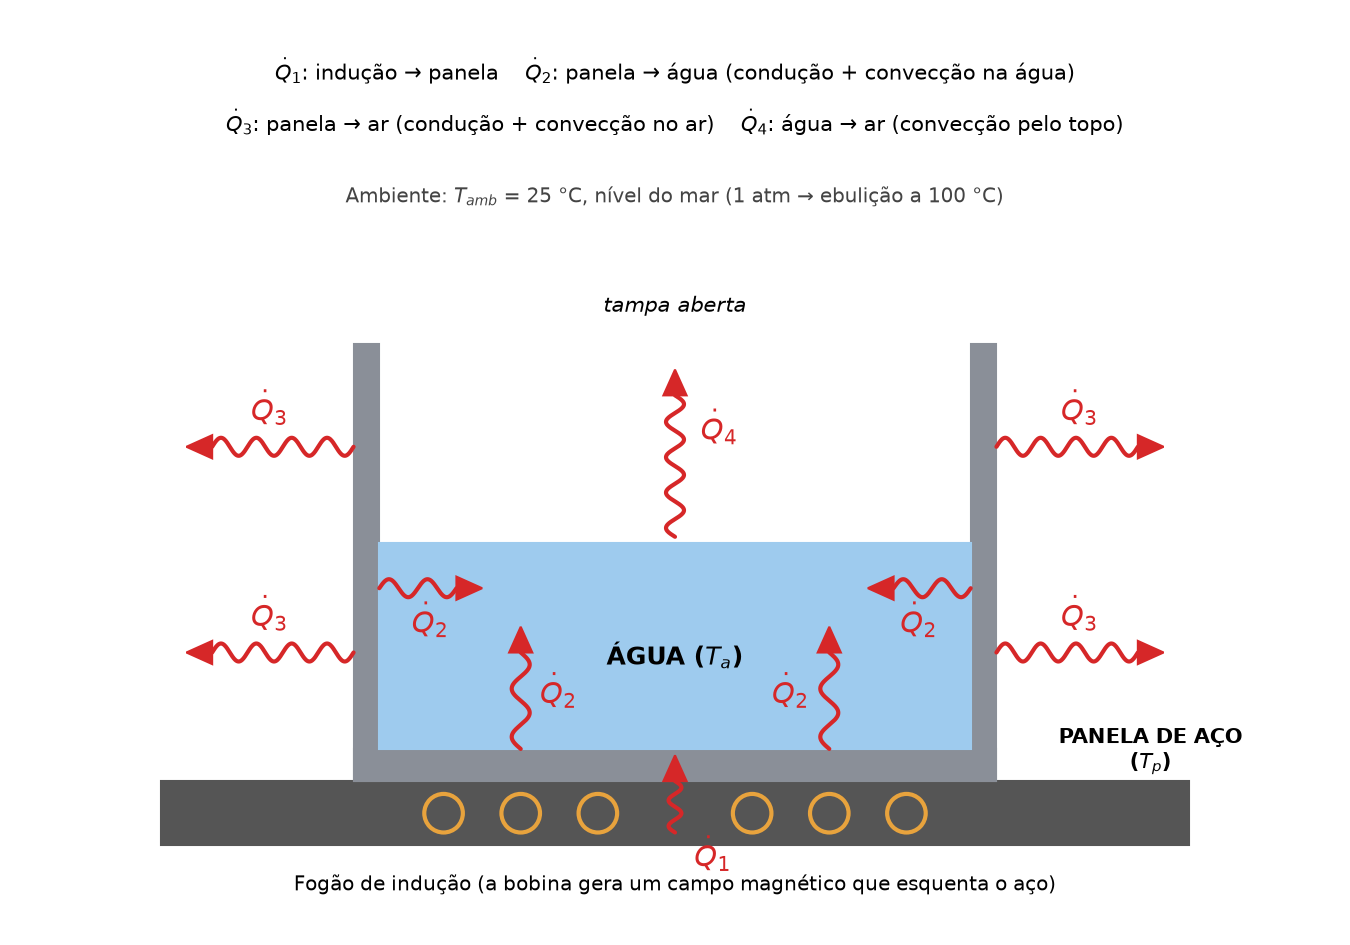
</div>

- $\dot{Q}_1$: calor gerado pelo fogão de indução no fundo da panela.
- $\dot{Q}_2$: calor da panela para a água (condução na parede + convecção na água).
- $\dot{Q}_3$: calor da panela para o ar pelas paredes, em toda a altura (condução na parede + convecção no ar).
- $\dot{Q}_4$: calor da água para o ar pelo topo aberto (convecção).

### 2.2 - Diagrama de estoques e fluxos

<div style="text-align: center;">
    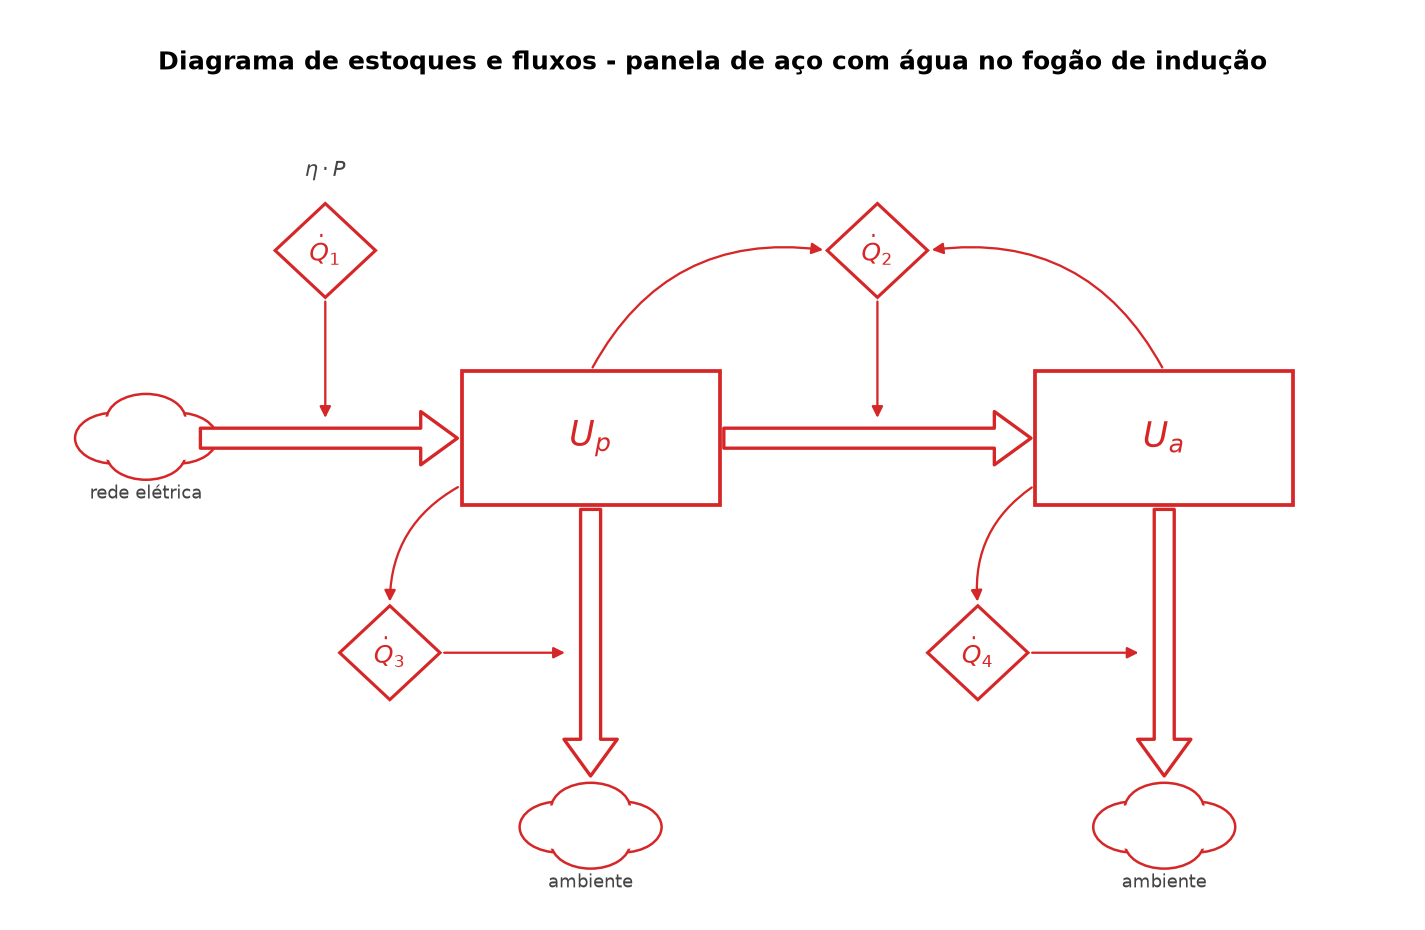
</div>

- $U_p$: energia interna da panela
- $U_a$: energia interna da água

### 2.3 - Equações diferenciais

**Balanço de energia** (o que entra menos o que sai de cada estoque):

$$
\left\{
    \begin{array}{l}
        \dfrac{dU_p}{dt} = \dot{Q}_1 - \dot{Q}_2 - \dot{Q}_3 \\
        \dfrac{dU_a}{dt} = \dot{Q}_2 - \dot{Q}_4 \\
    \end{array}
\right.
$$

**Fluxos de calor.** $\dot{Q}_1 = \eta \cdot P$ é a potência útil do fogão. Como na latinha da Aula 15, $\dot{Q}_2$, $\dot{Q}_3$ e $\dot{Q}_4$ são escritos com **resistências térmicas**, $\dot{Q} = \dfrac{\Delta T}{R}$:

<div style="text-align: center;">
    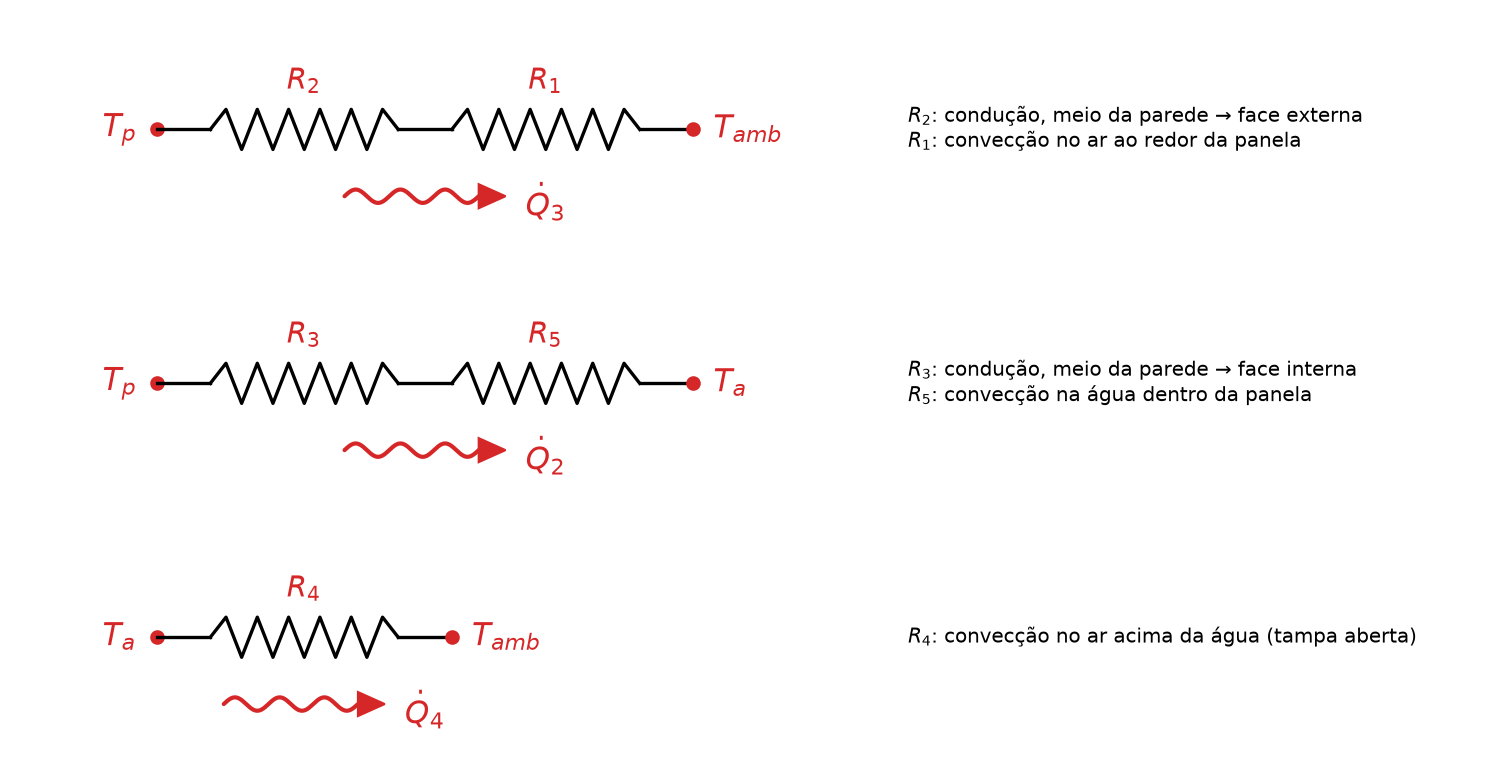
</div>

- $R_1$: resistência de **convecção** no ar ao redor da panela.
- $R_2$: resistência de **condução** do "meio" da parede até a face externa, ao longo de uma espessura $\frac{d}{2}$.
- $R_3$: resistência de **condução** do "meio" da parede até a face interna, que está em contato com a água, ao longo de uma espessura $\frac{d}{2}$.
- $R_4$: resistência de **convecção** no ar acima da superfície da água (tampa aberta).
- $R_5$: resistência de **convecção** na água, do lado de dentro da panela.

$$R_1 = \frac{1}{h_{ar} \cdot A_{lat}} \qquad R_2 = \frac{d/2}{k_{aço} \cdot A_{lat}} \qquad R_3 = \frac{d/2}{k_{aço} \cdot A_{pa}} \qquad R_4 = \frac{1}{h_{ar} \cdot A_{sup}} \qquad R_5 = \frac{1}{h_{agua} \cdot A_{pa}}$$

$$\dot{Q}_2 = \frac{T_p - T_a}{R_3 + R_5} \qquad \dot{Q}_3 = \frac{T_p - T_{amb}}{R_1 + R_2} \qquad \dot{Q}_4 = \frac{T_a - T_{amb}}{R_4}$$

Nessas fórmulas:
- $T_p$: temperatura da panela [°C].
- $T_a$: temperatura da água [°C].
- $T_{amb}$: temperatura do ar ambiente [°C], que é constante.

$T_p$ e $T_a$ **não têm um valor fixo**: elas mudam com o tempo e são justamente o que o modelo calcula (com o `odeint`). O que definimos é só o valor delas no início, em $t = 0$ (ver seção 2.4).

**Equações para o `odeint`.** Como $\dfrac{dU}{dt} = m \cdot c \cdot \dfrac{dT}{dt}$:

$$
\left\{
    \begin{array}{l}
        \dfrac{dT_p}{dt} = \dfrac{1}{m_p \cdot c_p} \cdot \left( \eta \cdot P - \dfrac{T_p - T_a}{R_3 + R_5} - \dfrac{T_p - T_{amb}}{R_1 + R_2} \right) \\[4mm]
        \dfrac{dT_a}{dt} = \dfrac{1}{m_a \cdot c_a} \cdot \left( \dfrac{T_p - T_a}{R_3 + R_5} - \dfrac{T_a - T_{amb}}{R_4} \right) \\
    \end{array}
\right.
$$

**De onde vem cada fórmula** (apostila, Aulas 14 a 16):

| Fórmula | Origem |
|---|---|
| $\dfrac{dU}{dt} = \sum \dot{Q}_{entra} - \sum \dot{Q}_{sai}$ | 1ª Lei da Termodinâmica (sem trabalho) |
| $\dfrac{dU}{dt} = m \cdot c \cdot \dfrac{dT}{dt}$ | calor sensível, $Q = m \cdot c \cdot \Delta T$ |
| $\dot{Q}_1 = \eta \cdot P$ | rendimento: potência útil = rendimento × potência elétrica |
| $R_{cond} = \dfrac{L}{k \cdot A}$ | lei de Fourier (condução) |
| $R_{conv} = \dfrac{1}{h \cdot A}$ | lei de Newton do resfriamento (convecção) |

### 2.4 - Parâmetros

| Parâmetro | Símbolo | Valor | Unidade | Origem |
|---|---|---|---|---|
| raio da panela | $r$ | 0,09 | m | panela comum de 18 cm (**medir**) |
| altura da panela | $H$ | 0,10 | m | panela comum (**medir**) |
| espessura da parede | $d$ | 0,001 | m | chapa de inox típica |
| massa da panela | $m_p$ | 0,8 | kg | panela comum (**pesar**) |
| calor específico do aço | $c_p$ | 500 | J/(kg·K) | tabela |
| condutividade do aço | $k_{aço}$ | 16 | W/(m·K) | tabela |
| massa de água | $m_a$ | 1,0 | kg | 1 L |
| calor específico da água | $c_a$ | 4186 | J/(kg·K) | tabela |
| potência elétrica do fogão | $P$ | 1500 | W | varia no gráfico conclusivo |
| eficiência da indução | $\eta$ | 0,85 | - | típico: 0,84 a 0,90 |
| convecção no ar | $h_{ar}$ | 10 | W/(m²·K) | tabela: convecção natural em gases, 2 a 25 |
| convecção na água | $h_{agua}$ | 500 | W/(m²·K) | tabela: convecção natural em líquidos, 50 a 1000 |
| temperatura ambiente | $T_{amb}$ | 25 | °C | condição ambiente |
| temperatura de ebulição | $T_{eb}$ | 100 | °C | nível do mar |

**Condições iniciais** (em $t = 0$ a panela e a água estão na temperatura ambiente):

| Variável | Símbolo | Valor inicial | Unidade |
|---|---|---|---|
| temperatura da panela | $T_p(0)$ | 25 | °C |
| temperatura da água | $T_a(0)$ | 25 | °C |

**Áreas:**
- $A_{sup} = \pi r^2$: topo da água.
- $A_{pa} = \pi r^2 + 2 \pi r \cdot H_{agua}$: panela em contato com a água, sendo $H_{agua}$ a altura da água.
- $A_{lat} = 2 \pi r H$: lateral da panela.

Usamos a potência **elétrica** $P$, e não a útil, porque é o valor que se escolhe no fogão e que se conhece no experimento.

Fontes dos valores de tabela: engineeringtoolbox.com e Incropera, *Fundamentos de Transferência de Calor e de Massa*.

In [ ]:
# ---------------- Panela ----------------
r = 0.09          # raio [m]
H = 0.10          # altura [m]
d = 0.001         # espessura da parede [m]
m_p = 0.8         # massa [kg]
c_p = 500         # calor específico do aço [J/(kg.K)]
k_aco = 16        # condutividade térmica do aço [W/(m.K)]

# ---------------- Água ----------------
m_a = 1.0         # massa [kg] (1 L)
c_a = 4186        # calor específico [J/(kg.K)]

# ---------------- Fogão e ambiente ----------------
P = 1500          # potência elétrica [W]
eta = 0.85        # eficiência da indução [-]
h_ar = 10         # coef. de convecção do ar [W/(m2.K)]
h_agua = 500      # coef. de convecção da água [W/(m2.K)]
T_amb = 25        # temperatura ambiente [°C]
T_eb = 100        # temperatura de ebulição [°C]

# ---------------- Condições iniciais ----------------
T_p0 = 25         # temperatura inicial da panela [°C]
T_a0 = 25         # temperatura inicial da água [°C]

# ---------------- Áreas [m2] ----------------
A_sup = np.pi * r**2                      # topo da água
H_agua = (m_a / 1000) / A_sup             # altura da água [m]
A_pa = A_sup + 2 * np.pi * r * H_agua     # panela em contato com a água
A_lat = 2 * np.pi * r * H                 # lateral da panela

# ---------------- Resistências térmicas [K/W] ----------------
R1 = 1 / (h_ar * A_lat)                   # convecção: ar ao redor da panela
R2 = (d / 2) / (k_aco * A_lat)            # condução: meio da parede -> face externa
R3 = (d / 2) / (k_aco * A_pa)             # condução: meio da parede -> face interna (água)
R4 = 1 / (h_ar * A_sup)                   # convecção: ar acima da superfície da água
R5 = 1 / (h_agua * A_pa)                  # convecção: água dentro da panela

---
## 3. Implementação

### 3.1 - Função do modelo

A função `modelo` é a que o `odeint` usa para resolver as equações da seção 2.3.

Ela recebe, nessa ordem:
- Uma **lista** com $T_p(t)$ e $T_a(t)$
- O instante de tempo $t$

E devolve:
- Uma **lista** com as taxas de variação $\dfrac{dT_p}{dt}$ e $\dfrac{dT_a}{dt}$

Dentro dela calculamos os fluxos de calor $\dot{Q}_1$, $\dot{Q}_2$, $\dot{Q}_3$ e $\dot{Q}_4$ com as resistências $R_1$ a $R_5$ da seção 2.4.

In [ ]:
def modelo(x, t):
    T_p = x[0]    # temperatura da panela [°C]
    T_a = x[1]    # temperatura da água [°C]

    # Fluxos de calor [W]
    Q1 = eta * P                       # fogão -> panela
    Q2 = (T_p - T_a) / (R3 + R5)       # panela -> água
    Q3 = (T_p - T_amb) / (R1 + R2)     # panela -> ar
    Q4 = (T_a - T_amb) / R4            # água -> ar

    # Taxas de variação das temperaturas [°C/s]
    dTpdt = (Q1 - Q2 - Q3) / (m_p * c_p)
    dTadt = (Q2 - Q4) / (m_a * c_a)

    dxdt = [dTpdt, dTadt]
    return dxdt

### 3.2 - Gráfico das temperaturas

Usando a função `modelo`, resolvemos as equações com o `odeint` para $P = 1500\ W$, com uma lista de tempo de $0$ a $3600\ s$ (1 hora) e passo de $1\ s$, partindo das condições iniciais $T_p(0) = T_a(0) = 25\ °C$.

Com um `while`, achamos o instante em que a água chega a $100\ °C$. Como desprezamos a evaporação, o modelo só vale até a água ferver, então o gráfico vai só até esse instante.

In [ ]:
# Define condições iniciais T_p(0) e T_a(0) e lista de tempo
x0 = [T_p0, T_a0]
dt = 1                               # passo de tempo [s]
t_lista = np.arange(0, 3600, dt)     # tempo [s]

x = odeint(modelo, x0, t_lista)
T_p_lista = x[:, 0]
T_a_lista = x[:, 1]

# Procura o instante em que a água ferve
i = 0
while i < len(t_lista) - 1 and T_a_lista[i] < T_eb:
    i = i + 1

print(f"Com P = {P} W, a água ferve em {t_lista[i]} s = {t_lista[i]/60:.1f} min")

# Plota só até a água ferver (tempo em minutos)
plt.plot(t_lista[:i+1] / 60, T_p_lista[:i+1], 'gray', label='Panela - $T_p$')
plt.plot(t_lista[:i+1] / 60, T_a_lista[:i+1], 'b', label='Água - $T_a$')
plt.axhline(T_eb, color='r', linestyle='--', label='Ebulição (100 °C)')

# Configura gráfico
plt.xlabel('Tempo (min)')
plt.ylabel('Temperatura (°C)')
plt.title(f'Temperaturas da panela e da água com P = {P} W')
plt.legend()
plt.grid(True)
plt.show()